# Exploration of the usable curves

This notebook is a first look at the data that `main.py` leaves in `data/processed`. It does not run the pipeline.

In [1]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join("..", "..")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image

from src.config import GROUPS, COLORS
from src.preprocessing.optimized import build_curve_data_groupby
from src.visualization import plots

processed = os.path.join("..", "..", "data", "processed")
tables = os.path.join("..", "..", "results", "tables")
figures = os.path.join("..", "..", "results", "figures")
usable = pd.read_csv(os.path.join(processed, "usable_curves.csv"), index_col="layer_id")
points_table = pd.read_csv(os.path.join(processed, "selected_points.csv"))
dataset = pd.read_csv(os.path.join(processed, "features.csv"), index_col="layer_id")
curve_data = build_curve_data_groupby(points_table)

## Cleaning steps

In [2]:
steps = pd.read_csv(os.path.join(processed, "cleaning_steps.csv"))
steps

,step,rows,curves
0,raw file,136989,15259
1,without duplicates,132447,15259
2,good quality fits,112708,11705
3,without missing values,112703,11705
4,psi <= 100000 m,112652,11705
5,physical range,112652,11705
6,tropical climate,10322,1122


Each row is the data after one filter. The biggest losses of curves are the quality filter and the selection of the tropical climate.

In [3]:
print("usable curves:", len(usable), "| points:", len(points_table))
print("sites:", usable["profile_id"].nunique(), "| references:", usable["reference"].nunique())
print(usable["texture_group"].value_counts()[GROUPS])

usable curves: 940 | points: 9053
sites: 270 | references: 8
texture_group
coarse    538
medium    170
fine      232
Name: count, dtype: int64


## Curves by texture group

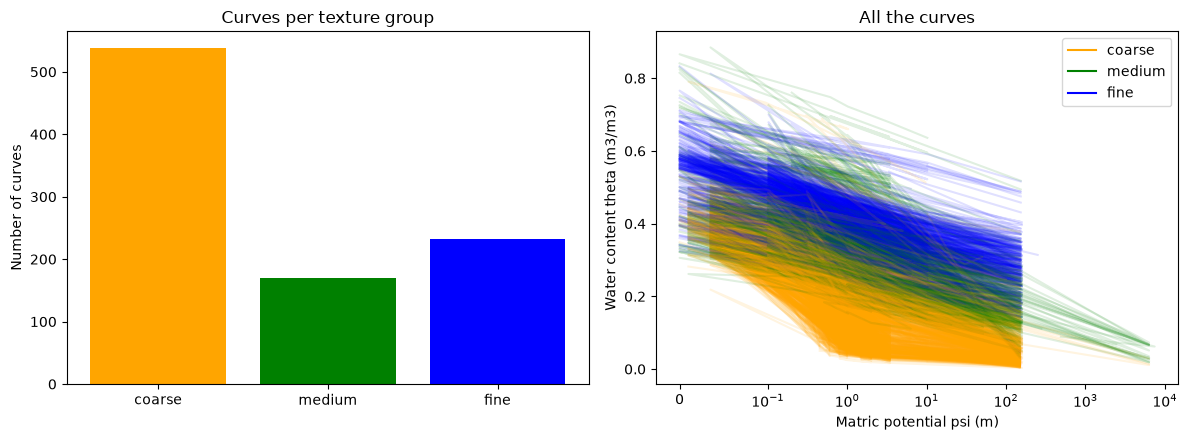

In [4]:
fig = plots.plot_group_counts_and_curves(usable, curve_data, GROUPS)
plt.show()

The coarse group has the most curves. For the same potential, the coarse curves have less water than the fine ones, and they lose water earlier.

## Sources of the data

In [5]:
pd.crosstab(usable["reference"], usable["texture_group"], margins=True)[GROUPS + ["All"]]

texture_group,coarse,medium,fine,All
reference,,,,
Cooper_et_al_2017,16,0,0,16
Grunwald_2020,445,52,2,499
Konyai_et_al_2006,4,1,0,5
Leenaars_et_al_2014,61,68,54,183
Medina_et_al_2002,0,0,1,1
Oliveira et al_2019,0,1,0,1
Ottoni_et_al_2018,12,47,175,234
Thakur_et_al_2007,0,1,0,1
All,538,170,232,940


In [6]:
curves_per_site = usable.groupby("profile_id").size()
print("median curves per site:", curves_per_site.median(), "| maximum:", curves_per_site.max())
print("curves with a rise of theta larger than 0.05:", int(usable["has_upward_jump"].sum()))
print("share of the curves of the biggest reference:", round(usable["reference"].value_counts().iloc[0] / len(usable), 2))

median curves per site: 3.0 | maximum: 10
curves with a rise of theta larger than 0.05: 4
share of the curves of the biggest reference: 0.53


One reference gives about half of the curves, and each texture group comes mostly from a few references. So texture and source are related. The curves of one site are very similar, and this is why the training and test sets are split by site.

## One example of each group

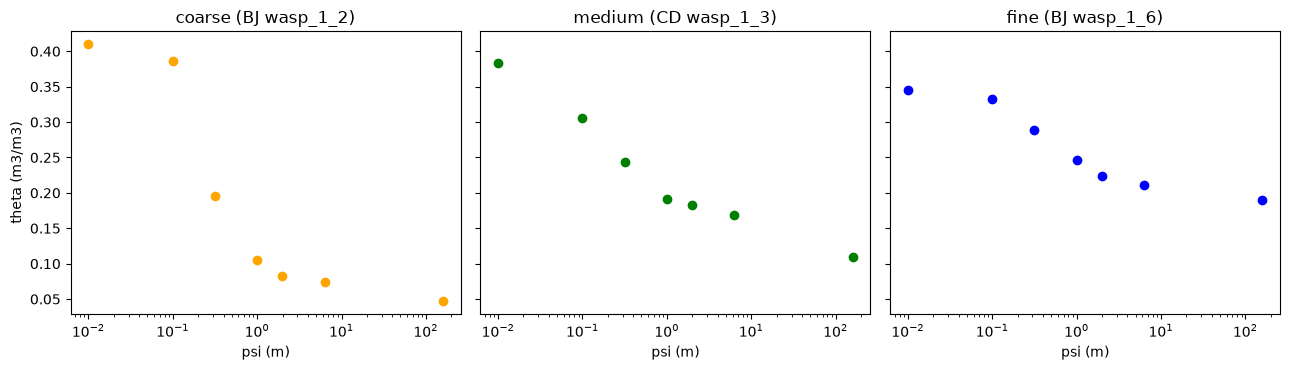

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, group in zip(axes, GROUPS):
    layer_id = dataset[dataset["texture_group"] == group].index[0]
    psi, theta = curve_data[layer_id]
    ax.plot(psi, theta, "o", color=COLORS[group])
    ax.set_xscale("log")
    ax.set_title(group + " (" + str(layer_id) + ")")
    ax.set_xlabel("psi (m)")
axes[0].set_ylabel("theta (m3/m3)")
plt.tight_layout()
plt.show()

Each curve has only about ten points, so the features of the shape are computed with few data.